In [12]:
from pathlib import Path

import pandas as pd

colunas = [
    "id",
    "diagnosis",
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave_points_mean",
    "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se",
    "texture_se",
    "perimeter_se",
    "area_se",
    "smoothness_se",
    "compactness_se",
    "concavity_se",
    "concave_points_se",
    "symmetry_se",
    "fractal_dimension_se",
    "radius_worst",
    "texture_worst",
    "perimeter_worst",
    "area_worst",
    "smoothness_worst",
    "compactness_worst",
    "concavity_worst",
    "concave_points_worst",
    "symmetry_worst",
    "fractal_dimension_worst",
]

caminho_dados = Path("data/raw/wdbc.data")
if not caminho_dados.exists():
    caminho_dados = Path("../data/raw/wdbc.data")
if not caminho_dados.exists():
    raise FileNotFoundError(
        "Não encontrei data/raw/wdbc.data. Execute o notebook a partir da pasta do projeto."
    )

df = pd.read_csv(caminho_dados, header=None, names=colunas)


In [13]:
# Valores faltantes: quantidade por coluna
faltantes = df.isna().sum()
print(faltantes[faltantes > 0])

# Total de valores faltantes
print("Total de valores faltantes:", df.isna().sum().sum())

# Linhas completamente duplicadas
duplicadas = df[df.duplicated(keep=False)]
print("Linhas duplicadas:", df.duplicated().sum())
display(duplicadas)

# IDs repetidos
ids_repetidos = df[df.duplicated(subset="id", keep=False)]
print("IDs repetidos:", df["id"].duplicated().sum())
display(ids_repetidos)

Series([], dtype: int64)
Total de valores faltantes: 0
Linhas duplicadas: 0


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst


IDs repetidos: 0


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst


In [15]:
#retirnado id pois não é preditor
df_limpo = df.drop('id', axis=1)

df_limpo.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
display(df.dtypes.rename("tipo").to_frame())
#parecem ter o tipo certo de variavel

,tipo
diagnosis,str
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave_points_mean,float64
symmetry_mean,float64


In [16]:
#estatisticas e amplitude
X = df_limpo.drop(columns=["diagnosis"])

resumo = X.describe().T
resumo["amplitude"] = resumo["max"] - resumo["min"]
resumo["IQR"] = resumo["75%"] - resumo["25%"]

display(
    resumo[["mean", "std", "min", "25%", "50%", "75%", "max", "amplitude", "IQR"]]
    .round(3)
)

,mean,std,min,25%,50%,75%,max,amplitude,IQR
radius_mean,14.127,3.524,6.981,11.700,13.370,15.780,28.110,21.129,4.080
texture_mean,19.290,4.301,9.710,16.170,18.840,21.800,39.280,29.570,5.630
perimeter_mean,91.969,24.299,43.790,75.170,86.240,104.100,188.500,144.710,28.930
area_mean,654.889,351.914,143.500,420.300,551.100,782.700,2501.000,2357.500,362.400
smoothness_mean,0.096,0.014,0.053,0.086,0.096,0.105,0.163,0.111,0.019
compactness_mean,0.104,0.053,0.019,0.065,0.093,0.130,0.345,0.326,0.065
concavity_mean,0.089,0.080,0.000,0.030,0.062,0.131,0.427,0.427,0.101
concave_points_mean,0.049,0.039,0.000,0.020,0.034,0.074,0.201,0.201,0.054
symmetry_mean,0.181,0.027,0.106,0.162,0.179,0.196,0.304,0.198,0.034
fractal_dimension_mean,0.063,0.007,0.050,0.058,0.062,0.066,0.097,0.047,0.008


In [17]:
#contando os extremos
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

extremos = X.lt(limite_inferior) | X.gt(limite_superior)
contagem = extremos.sum().sort_values(ascending=False)

display(contagem[contagem > 0].rename("possíveis_extremos").to_frame())

,possíveis_extremos
area_se,65
radius_se,38
perimeter_se,38
area_worst,35
smoothness_se,30
fractal_dimension_se,28
compactness_se,28
symmetry_se,27
area_mean,25
fractal_dimension_worst,24


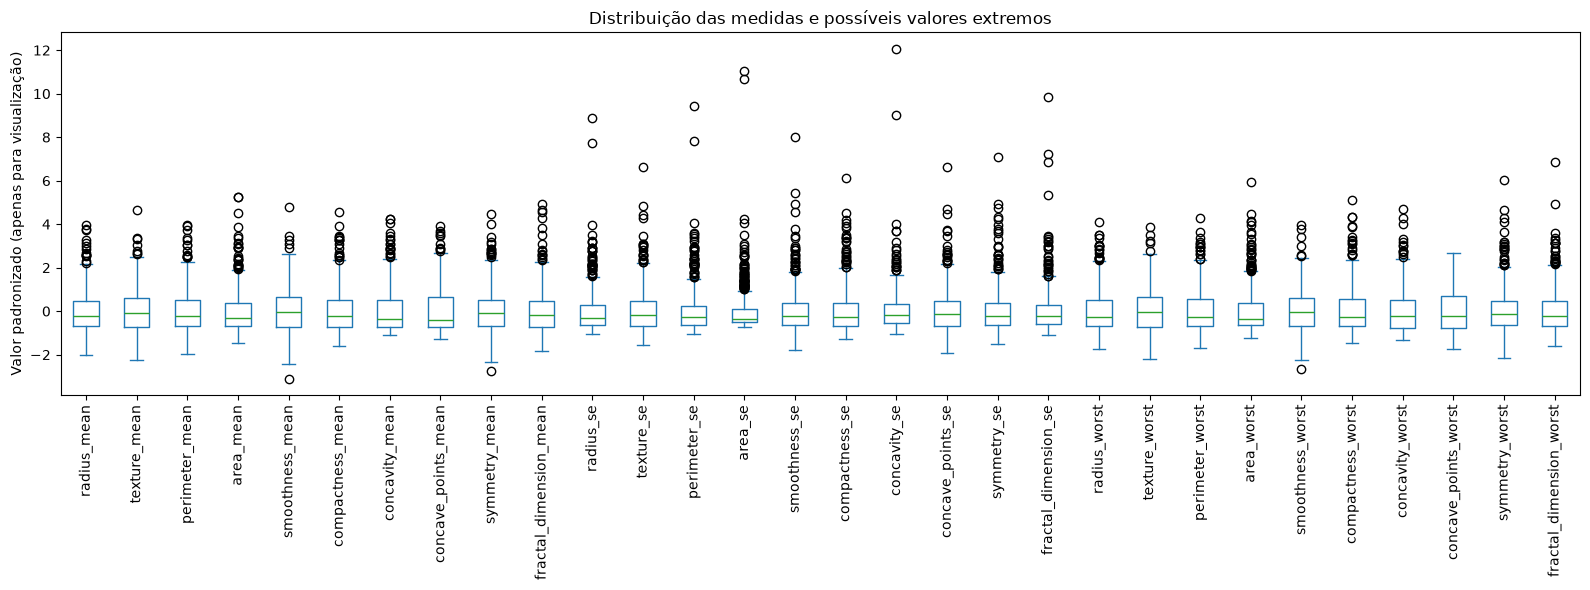

In [18]:
#um boxplot
import matplotlib.pyplot as plt

X_visualizacao = (X - X.mean()) / X.std()

ax = X_visualizacao.plot.box(figsize=(16, 6), showfliers=True, rot=90)
ax.set_ylabel("Valor padronizado (apenas para visualização)")
ax.set_title("Distribuição das medidas e possíveis valores extremos")
plt.tight_layout()
plt.show()

In [19]:
df_processado = df.copy()

df_processado["diagnosis"] = df_processado["diagnosis"].map({"B": 0, "M": 1})
if df_processado["diagnosis"].isna().any():
    raise ValueError("Há rótulos de diagnóstico inesperados.")

pasta_saida = Path("data/processed")
if not pasta_saida.exists():
    pasta_saida = Path("../data/processed")
pasta_saida.mkdir(parents=True, exist_ok=True)

arquivo_saida = pasta_saida / "wdbc_limpo.csv"
df_processado.to_csv(arquivo_saida, index=False)

print(f"Arquivo salvo em: {arquivo_saida}")

Arquivo salvo em: ..\data\processed\wdbc_limpo.csv
